# Лабораторная работа №6: Доверительные интервалы для математического ожидания

**Задание.**
1. Генерировать выборки разного размера из разных распределений, по каждой построить доверительный интервал для математического ожидания
   (с коэффициентом Стьюдента). Построить зависимость ширины интервала от размера выборки и от доверительной вероятности.
2. Проверить, совпадает ли назначенная доверительная вероятность $Q = 0{,}95$ с реально достигаемой: для $n = 10, 20, 30, 50, 60$
   сгенерировать по $N = 10^3$ выборок и посчитать, сколько интервалов действительно содержат точное математическое ожидание.

Распределения: нормальное $N(0, \sigma^2)$ (возьмём $\sigma = 2$) и равномерное $U[-1, 1]$.

## Теория

### Что такое доверительный интервал

Доверительный интервал для параметра $\theta$ с доверительной вероятностью $Q$ — это интервал $(\theta_L, \theta_U)$, концы которого вычисляются по выборке, такой что
$$
P(\theta_L < \theta < \theta_U) = Q .
$$
Случайны здесь **концы интервала**, а параметр $\theta$ — фиксированное число. Смысл $Q$: если много раз брать новую выборку и строить интервал,
то доля интервалов, накрывших $\theta$, будет близка к $Q$. Именно это проверяется в п. 2.

### Интервал Стьюдента для математического ожидания нормальной выборки

Пусть $X_1, \dots, X_n \sim N(\mu, \sigma^2)$ независимы, $\sigma$ неизвестна. Используем
$\bar x = \frac1n\sum x_i$ и исправленную оценку дисперсии $s^2 = \frac{1}{n-1}\sum (x_i - \bar x)^2$.

1. $\bar x \sim N\bigl(\mu, \frac{\sigma^2}{n}\bigr)$ (лаб. 5), поэтому $Z = \dfrac{(\bar x - \mu)\sqrt n}{\sigma} \sim N(0, 1)$.
   Построить интервал по $Z$ нельзя: $\sigma$ неизвестна.
2. По теореме Фишера (лаб. 5) $V = \dfrac{(n-1)s^2}{\sigma^2} \sim \chi^2_{n-1}$, и $V$ не зависит от $\bar x$, т.е. от $Z$.
3. **Распределение Стьюдента** с $k$ степенями свободы $t_k$ — это по определению распределение величины $\dfrac{Z}{\sqrt{V/k}}$,
   где $Z \sim N(0, 1)$ и $V \sim \chi^2_k$ независимы. Подставим наши $Z$ и $V$ при $k = n - 1$:
   $$
   T = \frac{Z}{\sqrt{V/(n-1)}} = \frac{(\bar x - \mu)\sqrt n / \sigma}{\sqrt{s^2/\sigma^2}} = \frac{(\bar x - \mu)\sqrt n}{s} \sim t_{n-1}.
   $$
   Неизвестная $\sigma$ сократилась — в $T$ входит только неизвестное $\mu$.
4. Распределение $t_{n-1}$ симметрично относительно нуля. Пусть $t_{p,\,n-1}$ — его квантиль уровня $p$ (т.е. $P(T < t_{p,\,n-1}) = p$),
   и $t = t_{\frac{1+Q}{2},\,n-1}$ — **коэффициент Стьюдента**. Тогда $P(T < -t) = \frac{1-Q}{2}$ и
   $$
   P(|T| < t) = \frac{1+Q}{2} - \frac{1-Q}{2} = Q .
   $$
5. Раскроем неравенство $\bigl|\bar x - \mu\bigr|\frac{\sqrt n}{s} < t \iff \bar x - t\frac{s}{\sqrt n} < \mu < \bar x + t\frac{s}{\sqrt n}$. Получаем интервал
   $$
   \boxed{\;\bar x - t_{\frac{1+Q}{2},\,n-1}\,\frac{s}{\sqrt n} \;<\; \mu \;<\; \bar x + t_{\frac{1+Q}{2},\,n-1}\,\frac{s}{\sqrt n}\;}
   $$
   Для нормальной выборки он **точный** при любом $n$: вероятность накрытия равна $Q$.

### Ширина интервала

$$
L = 2\,t_{\frac{1+Q}{2},\,n-1}\,\frac{s}{\sqrt n}.
$$

- **Рост $n$.** Ширина уменьшается по трём причинам: множитель $1/\sqrt n$; коэффициент Стьюдента убывает к квантили нормального
  распределения $u_{\frac{1+Q}{2}}$ (при малых $n$ у $t_{n-1}$ «тяжёлые хвосты», так компенсируется неточность $s$); $s$ всё меньше колеблется около $\sigma$.
  При больших $n$ $L \approx 2u_{\frac{1+Q}{2}}\sigma/\sqrt n$: чтобы сузить интервал вдвое, выборку надо увеличить в 4 раза.
- **Рост $Q$.** Квантиль $t_{\frac{1+Q}{2},\,n-1}$ растёт и стремится к $\infty$ при $Q \to 1$. Чем надёжнее интервал, тем он шире,
  т.е. тем менее точен.

**Средняя ширина.** $M[L] = \frac{2t}{\sqrt n}M[s]$, причём $M[s] < \sigma$ (так как $(M[s])^2 < M[s^2] = \sigma^2$ при $D[s] > 0$).
Для нормальной выборки $s = \sigma\sqrt{V/(n-1)}$ с $V \sim \chi^2_{k}$, $k = n-1$. Плотность $\chi^2_k$ равна
$f(v) = \frac{v^{k/2-1}e^{-v/2}}{2^{k/2}\Gamma(k/2)}$, и
$$
M[\sqrt V] = \int_0^\infty \frac{v^{(k+1)/2-1}e^{-v/2}}{2^{k/2}\Gamma(k/2)}\,dv = \frac{2^{(k+1)/2}\Gamma\bigl(\frac{k+1}{2}\bigr)}{2^{k/2}\Gamma\bigl(\frac k2\bigr)}
= \sqrt2\,\frac{\Gamma\bigl(\frac{k+1}{2}\bigr)}{\Gamma\bigl(\frac k2\bigr)}
$$
(интеграл сводится к интегралу от плотности $\chi^2_{k+1}$, умноженному на нормировку). Отсюда
$$
M[L] = \frac{2\,t_{\frac{1+Q}{2},\,n-1}\,\sigma}{\sqrt n}\,c_4(n), \qquad c_4(n) = \sqrt{\frac{2}{n-1}}\,\frac{\Gamma(n/2)}{\Gamma((n-1)/2)} .
$$
Для $U[-1, 1]$ точной формулы нет; при больших $n$ $M[s] \approx \sigma$ и $M[L] \approx 2t\sigma/\sqrt n$, где
$\sigma^2 = \int_{-1}^1 \frac{x^2}{2}\,dx = \frac13$.

### Что происходит для ненормального распределения

Вывод опирался на три факта: $\bar x$ нормально; $(n-1)s^2/\sigma^2 \sim \chi^2_{n-1}$; $\bar x$ и $s^2$ независимы. Для $U[-1, 1]$ ни один из них
точно не выполняется, поэтому реальная вероятность накрытия может отличаться от $Q$. Однако по центральной предельной теореме
$(\bar x - \mu)\sqrt n/\sigma \to N(0, 1)$, а по закону больших чисел $s \to \sigma$; значит, $T \to N(0, 1)$, и $t_{n-1} \to N(0, 1)$ тоже.
Поэтому при росте $n$ реальная доверительная вероятность стремится к $Q$, а при малых $n$ возможны отклонения.
У $U[-1, 1]$ распределение симметрично и не имеет хвостов, поэтому $\bar x$ становится близким к нормальному уже при небольших $n$.

### Как проверяется реальная доверительная вероятность

Для каждого $n$ строим интервалы по $N$ независимым выборкам и считаем число $K$ интервалов, содержащих $\mu$.
Каждый интервал накрывает $\mu$ независимо с одной и той же вероятностью $Q_{реал}$, поэтому $K \sim \mathrm{Bin}(N, Q_{реал})$ и оценка
$\hat Q = K/N$ имеет $M[\hat Q] = Q_{реал}$, $D[\hat Q] = Q_{реал}(1 - Q_{реал})/N$.
Если $Q_{реал} = 0{,}95$, то $\sqrt{D[\hat Q]} = \sqrt{0{,}95\cdot 0{,}05/1000} \approx 0{,}0069$, и по нормальному приближению с вероятностью 0,95
$$
\hat Q \in 0{,}95 \pm 1{,}96\cdot 0{,}0069 = [0{,}936;\ 0{,}964].
$$
Попадание $\hat Q$ в этот коридор означает, что отличие от 0,95 не обнаружено. При $N = 10^3$ заметить можно только отклонения больше ~1,4 %.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import gammaln

SEED = 42
N = 10**3
SIGMA_NORM = 2.0
DISTS = {
    'N(0, 2²)': dict(sample=lambda rng, size: rng.normal(0, SIGMA_NORM, size), mu=0.0, sigma=SIGMA_NORM),
    'U[-1, 1]': dict(sample=lambda rng, size: rng.uniform(-1, 1, size), mu=0.0, sigma=np.sqrt(1 / 3)),
}

plt.rcParams['figure.dpi'] = 110
rng = np.random.default_rng(SEED)


def student_ci(x, Q):
    """Интервал Стьюдента по каждой строке x: (нижняя граница, верхняя граница)."""
    n = x.shape[-1]
    half = stats.t.ppf((1 + Q) / 2, n - 1) * x.std(-1, ddof=1) / np.sqrt(n)
    return x.mean(-1) - half, x.mean(-1) + half


def c4(n):
    return np.sqrt(2 / (n - 1)) * np.exp(gammaln(n / 2) - gammaln((n - 1) / 2))


def mean_width_theory(n, Q, sigma, normal):
    return 2 * stats.t.ppf((1 + Q) / 2, n - 1) * sigma / np.sqrt(n) * (c4(n) if normal else 1.0)

## 1. Доверительные интервалы и их ширина

### Интервалы по отдельным выборкам

Для каждого распределения 50 выборок размера $n = 20$, $Q = 0{,}95$. Красным отмечены интервалы, не содержащие $\mu = 0$.

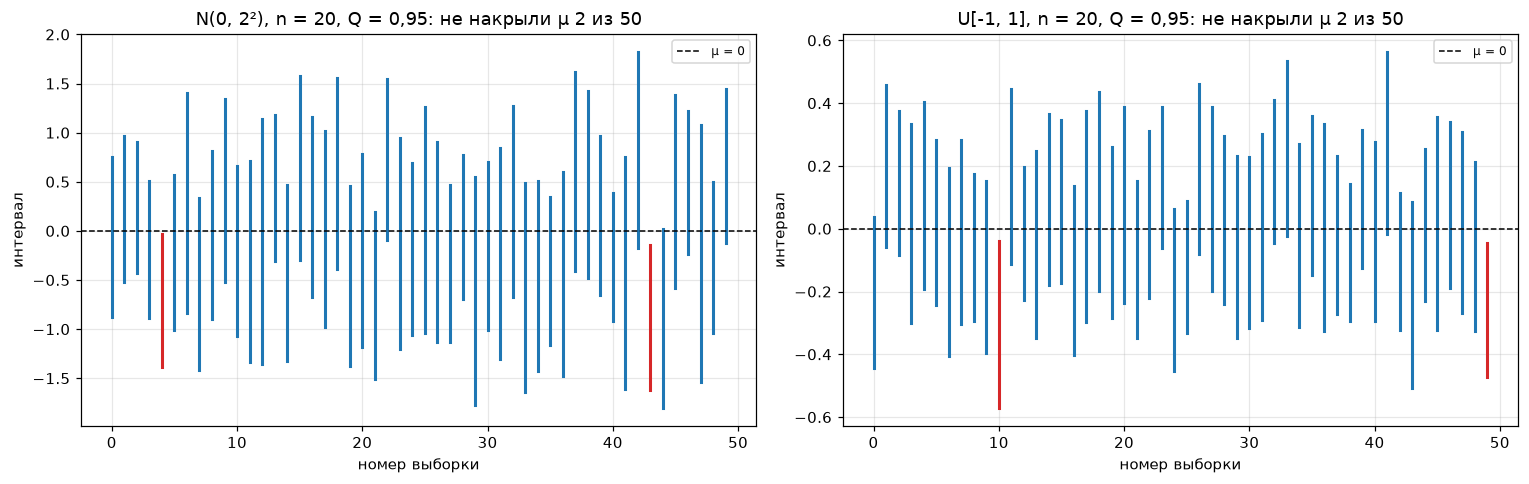

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (name, d) in zip(axes, DISTS.items()):
    lo, hi = student_ci(d['sample'](rng, (50, 20)), 0.95)
    miss = (lo > d['mu']) | (hi < d['mu'])
    for j in range(50):
        ax.plot([j, j], [lo[j], hi[j]], color='tab:red' if miss[j] else 'tab:blue', lw=2)
    ax.axhline(d['mu'], color='black', ls='--', lw=1, label='μ = 0')
    ax.set(title=f'{name}, n = 20, Q = 0,95: не накрыли μ {miss.sum()} из 50', xlabel='номер выборки', ylabel='интервал')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Зависимость ширины от $n$ и от $Q$

Для каждой пары $(n, Q)$ строим интервалы по $N = 10^3$ выборкам. Точки — средняя ширина, вертикальные отрезки — разброс ширины от выборки к выборке
(от 5%- до 95%-квантили), линии — теоретическая средняя ширина
(для $N(0, 2^2)$ точная, для $U[-1, 1]$ приближённая $2t\sigma/\sqrt n$).

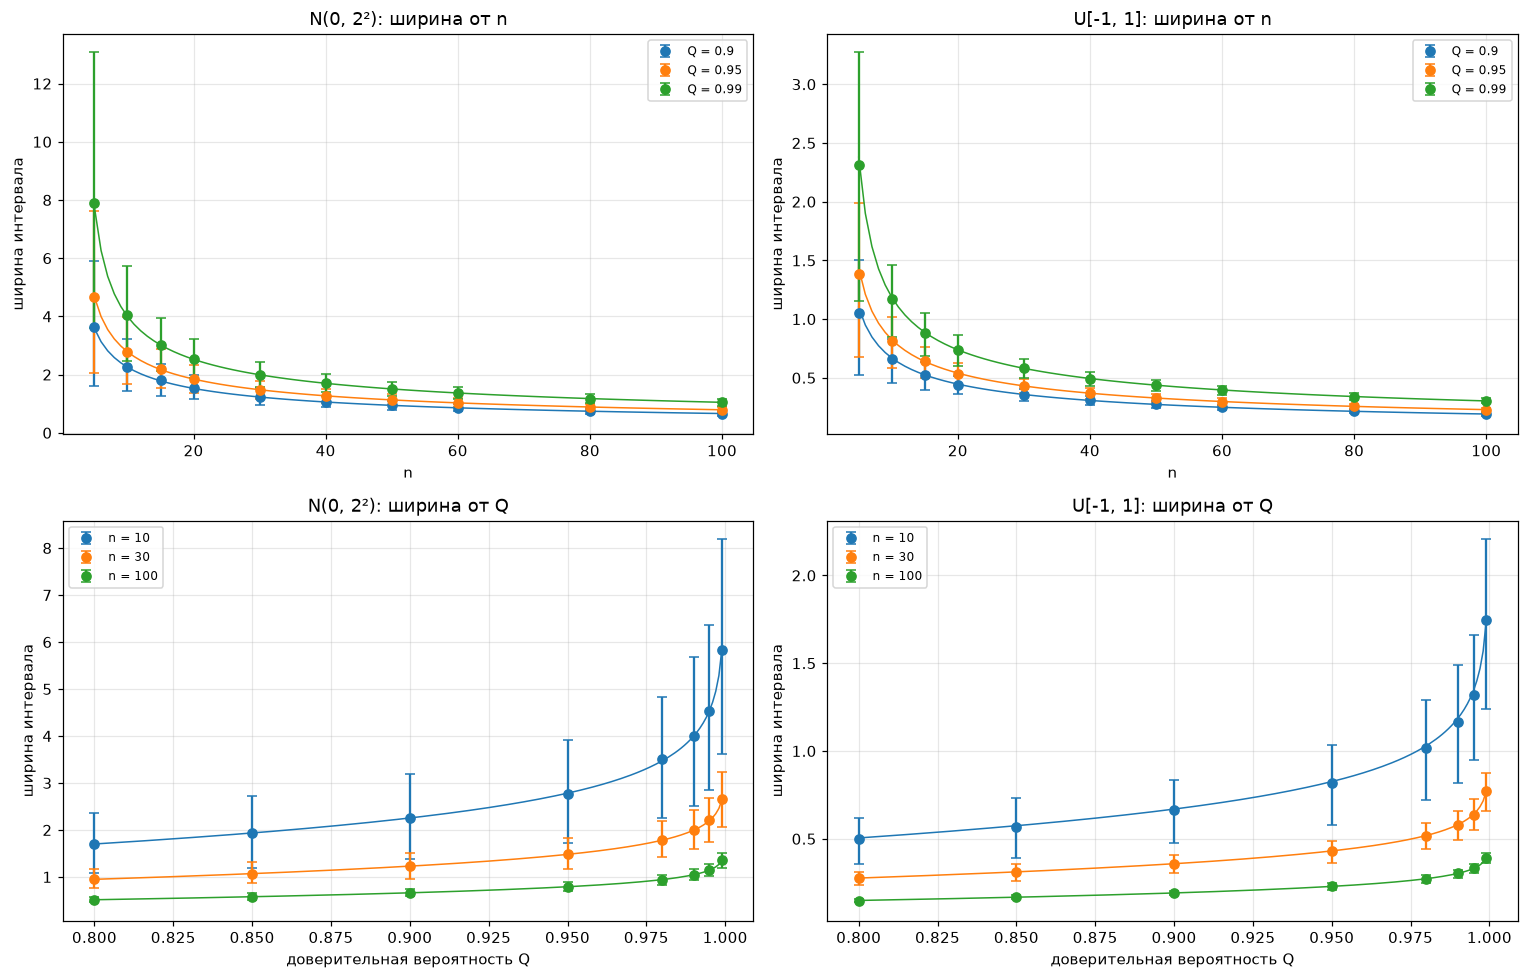

Коэффициент Стьюдента t_{(1+Q)/2, n-1}:
    n     Q=0.9    Q=0.95    Q=0.99
    5     2.132     2.776     4.604
   10     1.833     2.262     3.250
   30     1.699     2.045     2.756
  100     1.660     1.984     2.626
    ∞     1.645     1.960     2.576


In [3]:
NS_WIDTH = np.array([5, 10, 15, 20, 30, 40, 50, 60, 80, 100])
QS_PLOT = [0.90, 0.95, 0.99]
QS_WIDTH = np.array([0.80, 0.85, 0.90, 0.95, 0.98, 0.99, 0.995, 0.999])
NS_PLOT = [10, 30, 100]
colors = ['tab:blue', 'tab:orange', 'tab:green']


def widths(d, n, Q):
    lo, hi = student_ci(d['sample'](rng, (N, n)), Q)
    w = hi - lo
    return w.mean(), np.quantile(w, 0.05), np.quantile(w, 0.95)


fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for col, (name, d) in enumerate(DISTS.items()):
    normal = name.startswith('N')
    ax = axes[0, col]
    for Q, c in zip(QS_PLOT, colors):
        m, q05, q95 = np.array([widths(d, n, Q) for n in NS_WIDTH]).T
        ax.errorbar(NS_WIDTH, m, yerr=[m - q05, q95 - m], fmt='o', color=c, capsize=3, label=f'Q = {Q}')
        n_grid = np.arange(5, 101)
        ax.plot(n_grid, mean_width_theory(n_grid, Q, d['sigma'], normal), color=c, lw=1)
    ax.set(title=f'{name}: ширина от n', xlabel='n', ylabel='ширина интервала')

    ax = axes[1, col]
    for n, c in zip(NS_PLOT, colors):
        m, q05, q95 = np.array([widths(d, n, Q) for Q in QS_WIDTH]).T
        ax.errorbar(QS_WIDTH, m, yerr=[m - q05, q95 - m], fmt='o', color=c, capsize=3, label=f'n = {n}')
        q_grid = np.linspace(0.8, 0.999, 200)
        ax.plot(q_grid, mean_width_theory(n, q_grid, d['sigma'], normal), color=c, lw=1)
    ax.set(title=f'{name}: ширина от Q', xlabel='доверительная вероятность Q', ylabel='ширина интервала')
for ax in axes.flat:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print('Коэффициент Стьюдента t_{(1+Q)/2, n-1}:')
print(f'{"n":>5}' + ''.join(f'{"Q=" + str(Q):>10}' for Q in QS_PLOT))
for n in [5, 10, 30, 100]:
    print(f'{n:>5}' + ''.join(f'{stats.t.ppf((1 + Q) / 2, n - 1):>10.3f}' for Q in QS_PLOT))
print(f'{"∞":>5}' + ''.join(f'{stats.norm.ppf((1 + Q) / 2):>10.3f}' for Q in QS_PLOT))

### Выводы по п. 1

- Интервалы, построенные по разным выборкам, различаются и положением (центр $\bar x$ случаен), и шириной ($s$ случайна). Из 50 интервалов
  $\mu$ не накрыли по 2 для каждого распределения — при $Q = 0{,}95$ в среднем ожидается $2{,}5$.
- **Ширина убывает с ростом $n$**, быстрее всего при малых $n$: при $Q = 0{,}95$ для $N(0, 2^2)$ средняя ширина 4,67 при $n = 5$, 2,78 при $n = 10$, 0,79 при $n = 100$.
  При малых $n$ к множителю $1/\sqrt n$ добавляется убывание коэффициента Стьюдента ($t = 2{,}776$ при $n = 5$ против $1{,}984$ при $n = 100$).
  При больших $n$ ширина $\approx 2u\sigma/\sqrt n$: увеличение выборки в 4 раза (10 → 40) сужает интервал примерно вдвое (в 2,19 раза, чуть больше из-за коэффициента Стьюдента).
- **Ширина растёт с ростом $Q$**: медленно до $Q \approx 0{,}95$ и резко при $Q \to 1$. Переход от $Q = 0{,}95$ к $0{,}999$ расширяет интервал в 2,1 раза при $n = 10$
  и в 1,7 раза при $n = 100$ (при малых $n$ хвосты $t_{n-1}$ тяжелее). Чем выше требуемая надёжность, тем ниже точность.
- **Разброс ширины** от выборки к выборке велик при малых $n$ (при $n = 10$, $Q = 0{,}95$ для $N(0, 2^2)$ 90 % ширин лежат примерно от 1,7 до 3,9) и быстро
  уменьшается с ростом $n$, так как $s \to \sigma$.
- Для $N(0, 2^2)$ средняя ширина совпадает с точной формулой $2t\sigma c_4(n)/\sqrt n$. Для $U[-1, 1]$ приближение $2t\sigma/\sqrt n$ немного завышает ширину при малых $n$
  (на ≈4 % при $n = 5$, так как $M[s] < \sigma$) и практически точно уже при $n \ge 20$. Зависимости от $n$ и $Q$ для обоих распределений одинаковы по характеру:
  ширина пропорциональна $\sigma$, а у $U[-1, 1]$ $\sigma = 1/\sqrt3 \approx 0{,}58$ против $2$ у $N(0, 2^2)$.

## 2. Реальная доверительная вероятность при $Q = 0{,}95$

Доля интервалов, содержащих μ (N = 1000); коридор для Q = 0,95: [0.936; 0.964]
    n    N(0, 2²)    U[-1, 1]
   10       0.935       0.949
   20       0.946       0.940
   30       0.954       0.942
   50       0.941       0.955
   60       0.951       0.954


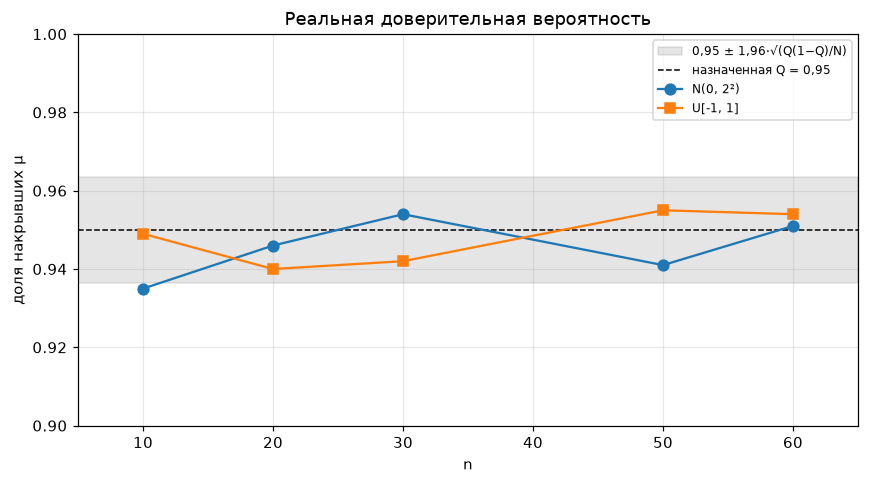

In [4]:
Q = 0.95
NS_COVER = [10, 20, 30, 50, 60]
band = 1.96 * np.sqrt(Q * (1 - Q) / N)

coverage = {}
for name, d in DISTS.items():
    coverage[name] = []
    for n in NS_COVER:
        lo, hi = student_ci(d['sample'](rng, (N, n)), Q)
        coverage[name].append(np.mean((lo < d['mu']) & (d['mu'] < hi)))

print(f'Доля интервалов, содержащих μ (N = {N}); коридор для Q = 0,95: [{Q - band:.3f}; {Q + band:.3f}]')
print(f'{"n":>5}' + ''.join(f'{name:>12}' for name in DISTS))
for i, n in enumerate(NS_COVER):
    print(f'{n:>5}' + ''.join(f'{coverage[name][i]:>12.3f}' for name in DISTS))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.fill_between([5, 65], Q - band, Q + band, color='gray', alpha=0.2, label='0,95 ± 1,96·√(Q(1−Q)/N)')
ax.axhline(Q, color='black', ls='--', lw=1, label='назначенная Q = 0,95')
for (name, cov), m in zip(coverage.items(), ['o', 's']):
    ax.plot(NS_COVER, cov, marker=m, ms=7, label=name)
ax.set(xlim=(5, 65), ylim=(0.9, 1.0), xlabel='n', ylabel='доля накрывших μ', title='Реальная доверительная вероятность')
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Выводы по п. 2

- **Нормальное распределение.** Реальная доля накрытий 0,935–0,954, в среднем по пяти $n$ — 0,945, т.е. близко к назначенной 0,95, как и должно быть:
  для нормальной выборки интервал Стьюдента точный. Значение 0,935 при $n = 10$ чуть ниже коридора $[0{,}936;\ 0{,}964]$ — это случайность:
  из 10 проверенных значений с вероятностью 0,05 каждое выходит за коридор и при точном $Q$, так что один такой выход ожидаем.
- **Равномерное распределение.** Доля накрытий 0,940–0,955, все значения внутри коридора: условия построения (нормальность выборки) нарушены,
  но заметного отличия реальной доверительной вероятности от 0,95 нет уже при $n = 10$. Причина — по центральной предельной теореме $\bar x$ быстро становится
  близким к нормальному, а у $U[-1, 1]$ распределение симметрично и без хвостов, так что приближение хорошее уже при малых $n$.
- При $N = 10^3$ точность оценки доли накрытий около $\pm 0{,}014$, поэтому отклонения меньше ~1,4 % этим экспериментом не обнаруживаются.
  Вывод: интервал Стьюдента для математического ожидания устойчив к отклонению от нормальности в случае равномерного распределения — назначенная $Q = 0{,}95$
  практически совпадает с реально достигаемой при всех исследованных $n$.